# 4.13 · Варіант 1. Класифікатор трьох типів техніки (transfer learning)

**Задача:** навчальний застосунок відносить фотографію до одного з трьох класів: **БПЛА**, **бронетехніка**, **вантажний автомобіль**, і показує впевненість.

| | |
|---|---|
| **Готова модель** | ResNet18, попередньо навчена на ImageNet-1k (1000 класів), `torchvision.models.resnet18(weights=IMAGENET1K_V1)`, PyTorch Hub / download.pytorch.org |
| **Що адаптовано** | фінальний шар `fc` (512 → 1000) замінено новим `fc` (512 → 3); порівняно два режими: лише новий шар та новий шар + розморожений останній блок `layer4` |
| **Дані** | відкриті знімки Wikimedia Commons (CC / public domain), очищені вручну; 20 навч. + 4 валід. на клас, решта — тест; окремий «складний» набір техніки інших типів |
| **Обмеження даних** | лише відкриті джерела; жодних матеріалів з обмеженим доступом чи реальних оперативних обставин |

Повний цикл: `scripts/fetch_images.py` → ручне очищення (`data/rejected.csv`) → `scripts/train.py` → `scripts/challenge.py` → `scripts/make_figures.py`. Застосунок: `app.py`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import CLASSES, CLASS_UA
m = json.load(open("results/metrics.json", encoding="utf-8"))
ch = json.load(open("results/challenge.json", encoding="utf-8"))
print("Розмір вибірок:", m["split_sizes"])

Розмір вибірок: {'train': 60, 'val': 12, 'test': 27}


## 1. Дані: звідки і скільки

In [2]:
cred = pd.read_csv("data/credits.csv")
clean = {c: len(list((ROOT/"data"/"clean"/c).glob("*.jpg"))) for c in CLASSES}
rej = pd.read_csv("data/rejected.csv")
pd.DataFrame({"клас": [CLASS_UA[c] for c in CLASSES],
              "завантажено": [int((cred["class"]==c).sum()) for c in CLASSES],
              "відкинуто вручну": [int(rej["file"].str.startswith(c+"/").sum()) for c in CLASSES],
              "у роботі": [clean[c] for c in CLASSES]})

,клас,завантажено,відкинуто вручну,у роботі
0,БПЛА,45,14,31
1,Бронетехніка,45,13,32
2,Вантажний автомобіль,45,9,36


In [3]:
print("Ліцензії:"); print(cred["license"].value_counts().to_string())
print("\nПричини відбору (приклади):"); print(rej.head(8).to_string(index=False))

Ліцензії:
license
Public domain      49
CC BY-SA 4.0       43
CC BY-SA 3.0       16
CC BY 4.0          11
CC BY-SA 2.0        7
CC0                 6
CC BY 2.0           2
CC BY-SA 3.0 de     1

Причини відбору (приклади):
           file          reason
uav/uav_001.jpg           карта
uav/uav_003.jpg стенд з текстом
uav/uav_005.jpg           карта
uav/uav_007.jpg           карта
uav/uav_009.jpg           карта
uav/uav_010.jpg           карта
uav/uav_011.jpg           марки
uav/uav_018.jpg         не БПЛА


## 2. Що змінено в моделі

In [4]:
from common import build_model
model = build_model(pretrained=False, unfreeze_layer4=True)
total = sum(p.numel() for p in model.parameters())
train_fc = sum(p.numel() for p in model.fc.parameters())
train_l4 = sum(p.numel() for p in model.layer4.parameters())
print(model.fc)
print(f"Усього параметрів: {total:,}")
print(f"Режим A — навчається лише fc: {train_fc:,} ({train_fc/total:.2%})")
print(f"Режим B — fc + layer4: {train_fc+train_l4:,} ({(train_fc+train_l4)/total:.1%})")

Linear(in_features=512, out_features=3, bias=True)
Усього параметрів: 11,178,051
Режим A — навчається лише fc: 1,539 (0.01%)
Режим B — fc + layer4: 8,395,267 (75.1%)


## 3. Навчання і якість

In [5]:
rows = []
names = {"feature_extraction": "A. Лише новий шар fc", "fine_tuning": "B. fc + розморожений layer4"}
for k in ["feature_extraction", "fine_tuning"]:
    rows.append({"режим": names[k], "валідація": m["modes"][k]["best_val_acc"],
                 "тест (27 знімків)": m["modes"][k]["test_acc"],
                 f"складний набір ({ch[k]['n']})": ch[k]["accuracy"]})
pd.DataFrame(rows).style.format({c: "{:.0%}" for c in list(rows[0])[1:]})

,режим,валідація,тест (27 знімків),складний набір (24)
0,A. Лише новий шар fc,92%,93%,71%
1,B. fc + розморожений layer4,100%,100%,88%


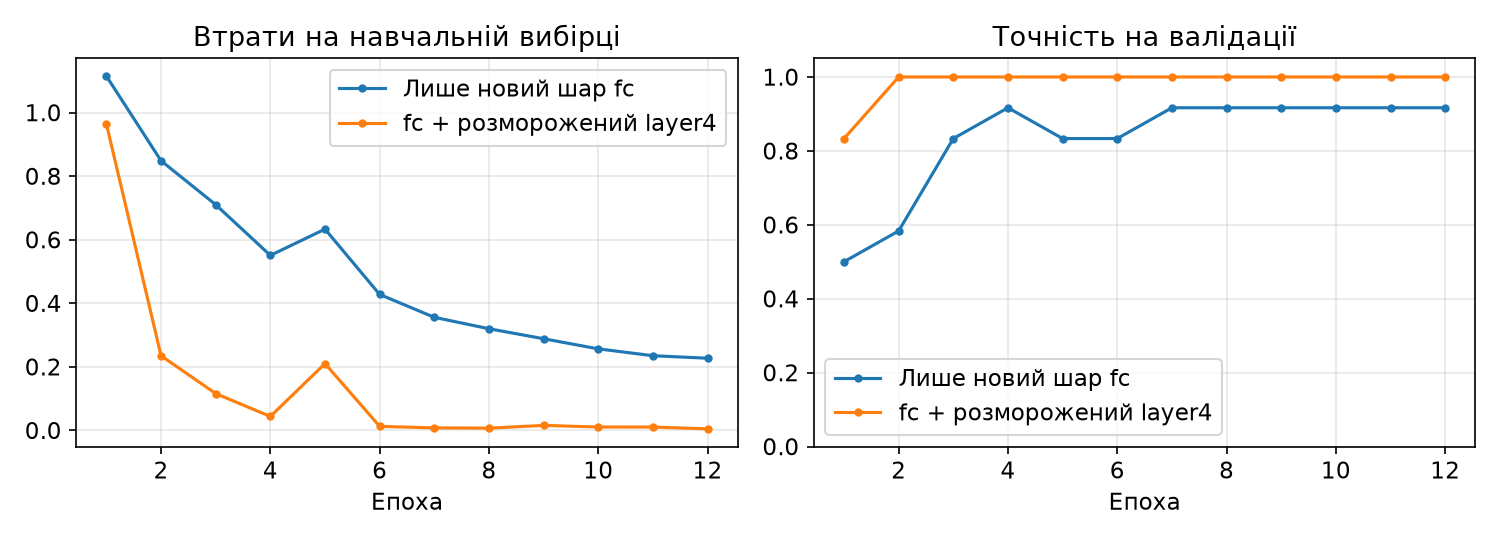

In [6]:
display(Image("results/training_curves.png", width=850))

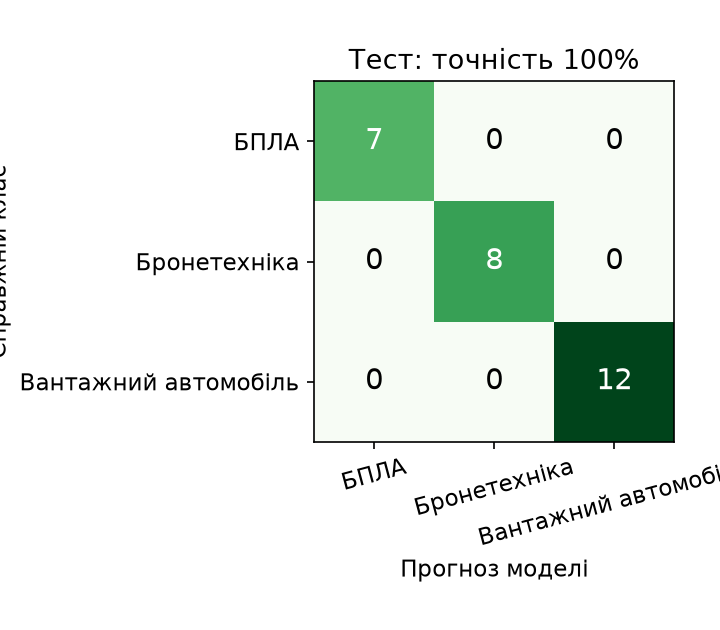

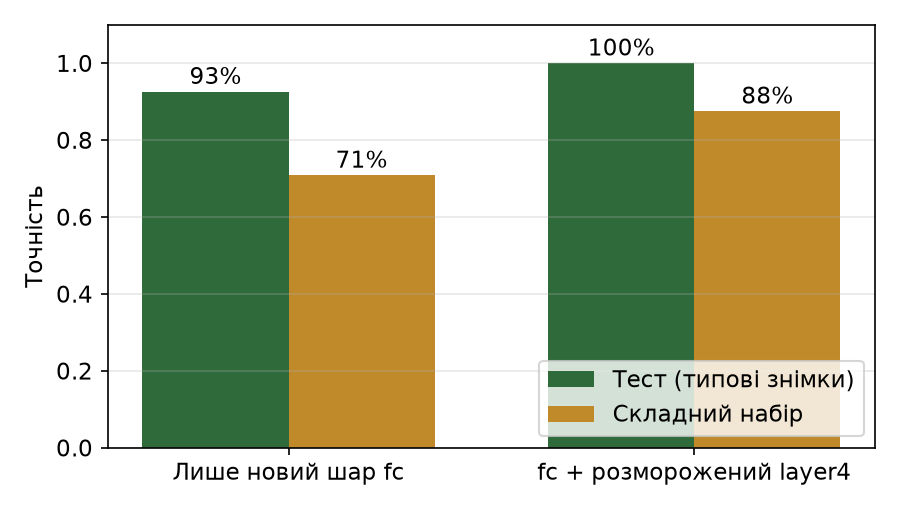

In [7]:
display(Image("results/confusion_matrix.png", width=420)); display(Image("results/accuracy_comparison.png", width=520))

## 4. Демонстрація: нові знімки → клас → впевненість
Знімки з тестової вибірки, яких модель не бачила під час навчання.

data/clean/uav/uav_008.jpg: БПЛА (впевненість 100%) | БПЛА 100%, Бронетехніка 0%, Вантажний автомобіль 0%
data/clean/armor/armor_001.jpg: Бронетехніка (впевненість 90%) | БПЛА 0%, Бронетехніка 90%, Вантажний автомобіль 10%
data/clean/armor/armor_037.jpg: Бронетехніка (впевненість 100%) | БПЛА 0%, Бронетехніка 100%, Вантажний автомобіль 0%
data/clean/truck/truck_004.jpg: Вантажний автомобіль (впевненість 70%) | БПЛА 6%, Бронетехніка 23%, Вантажний автомобіль 70%
data/challenge/uav/uav_009.jpg: БПЛА (впевненість 100%) | БПЛА 100%, Бронетехніка 0%, Вантажний автомобіль 0%



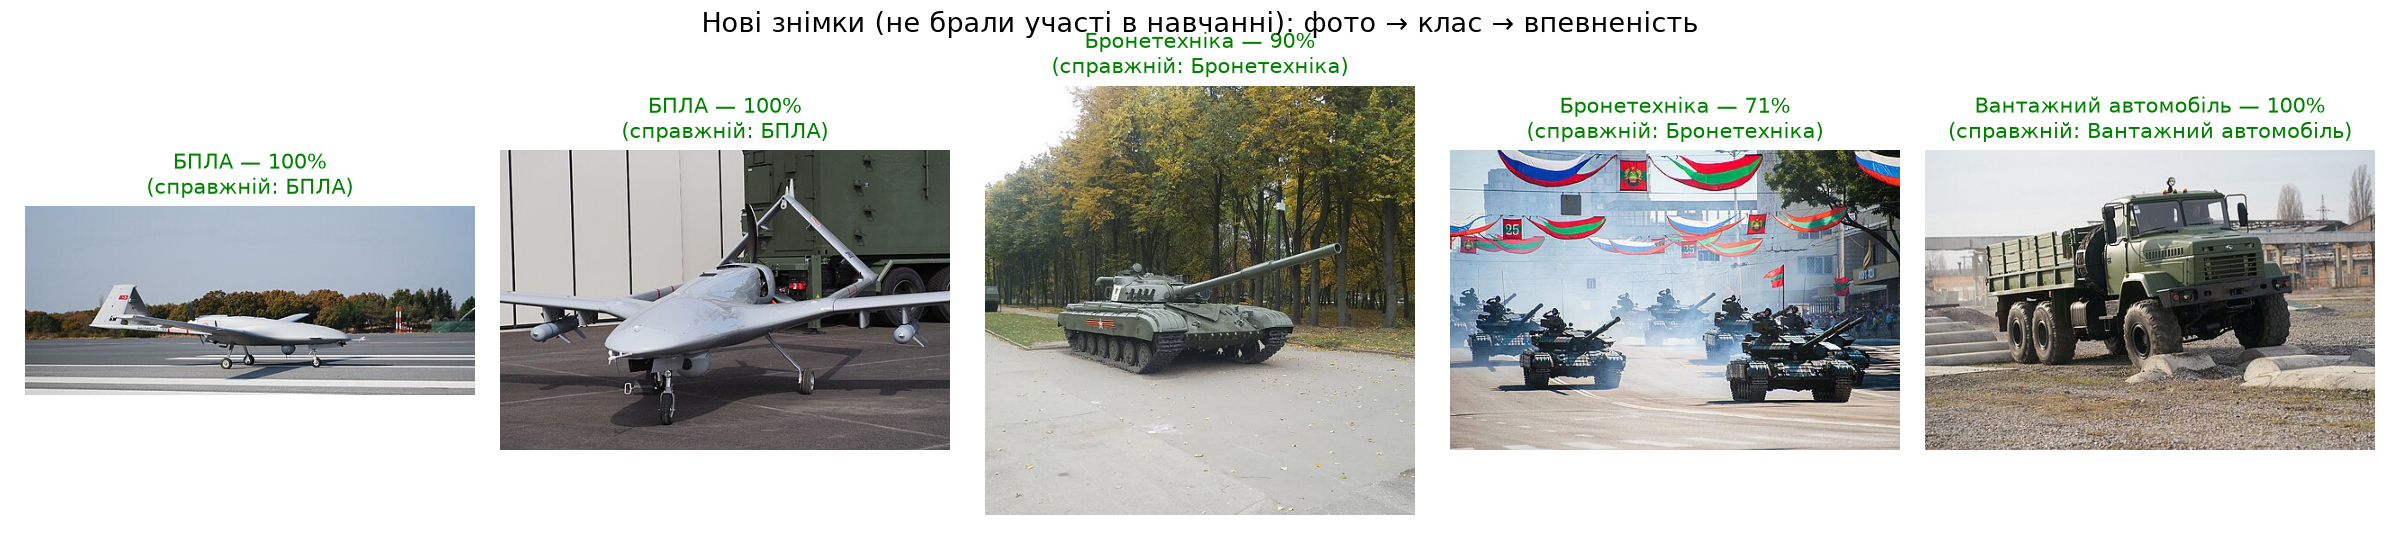

In [8]:
import subprocess
demo = ["data/clean/uav/uav_008.jpg", "data/clean/armor/armor_001.jpg", "data/clean/armor/armor_037.jpg",
        "data/clean/truck/truck_004.jpg", "data/challenge/uav/uav_009.jpg"]
print(subprocess.run([sys.executable, "scripts/predict.py", *demo], capture_output=True, text=True, encoding="utf-8").stdout)
display(Image("results/demo_new_images.png", width=950))

## 5. Помилки та їх пояснення

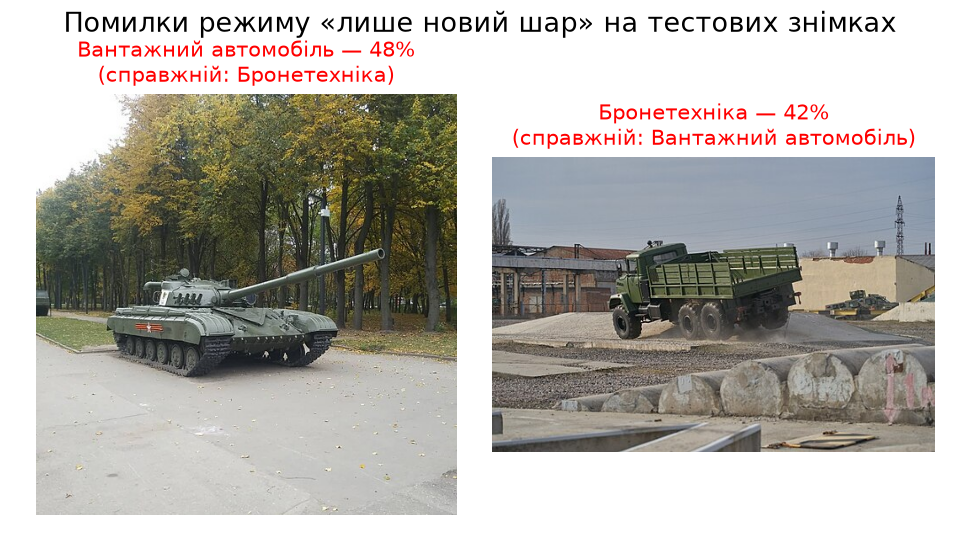

In [9]:
display(Image("results/errors_feature_extraction.png", width=650))

**Режим A (лише новий шар)** помиляється на тесті двічі: танк-пам’ятник Т-64 у парку на асфальті — «вантажівка»; KrAZ на полігоні серед бетонних блоків — «бронетехніка». Ймовірна причина — фон: без донавчання глибоких шарів модель частково орієнтується на оточення (асфальт/дорога ↔ вантажівки, полігон ↔ танки). Впевненість в обох випадках < 50 %: модель «вагається», а застосунок позначає це як низьку впевненість.

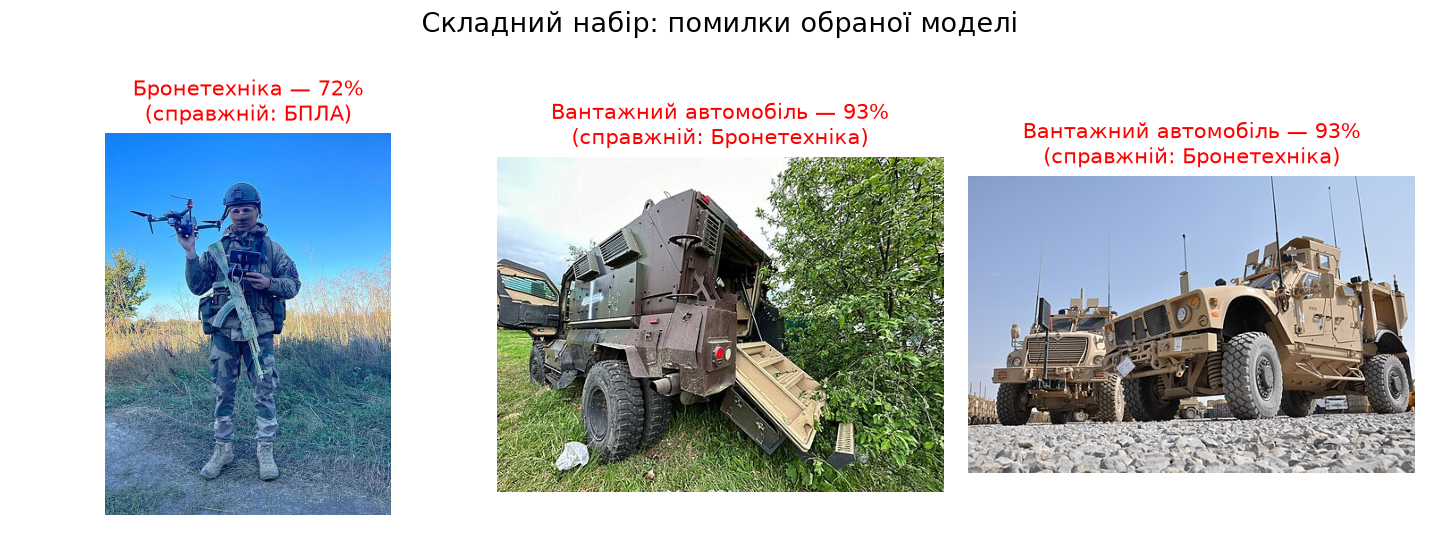

,знімок,справжній,прогноз,впевненість
0,uav/uav_004.jpg,БПЛА,Бронетехніка,72%
1,armor/armor_007.jpg,Бронетехніка,Вантажний автомобіль,93%
2,armor/armor_008.jpg,Бронетехніка,Вантажний автомобіль,93%


In [10]:
display(Image("results/errors_challenge.png", width=950))
pd.DataFrame([{"знімок": p["file"].split("/",2)[-1], "справжній": CLASS_UA[p["true"]], "прогноз": CLASS_UA[p["pred"]],
               "впевненість": f"{p['confidence']:.0%}"} for p in ch[m["selected_mode"]]["predictions"] if p["true"] != p["pred"]])

**Складний набір** (квадрокоптери, Bayraktar Akıncı, колісні БТР/MRAP, Unimog, Iveco, ГАЗ-66 — типів, яких не було в навчальних запитах):

* **MRAP MaxxPro / M-ATV → «вантажний автомобіль» (93 %)** — у навчальній вибірці бронетехніка була лише гусеничною (танки), тому модель засвоїла правило «колеса + кабіна = вантажівка». Це класичний зсув розподілу даних; висока впевненість на помилці — найнебезпечніший тип помилки.
* **Солдат із квадрокоптером → «бронетехніка» (72 %)** — дрон займає малу частку кадру, а камуфляж і зброя асоціюються з бронетехнікою.

Колісні БТР-80 і БМП-1 модель уже розпізнає правильно — розморожений `layer4` навчився загальніших ознак «броньованого корпусу».

## 6. Висновок

**Переваги повторного використання готової моделі.** Лише 60 навчальних знімків і ≈ 2 хв навчання на звичайному ноутбуці без GPU — і 100 % на тестовій вибірці (27 знімків) та 88 % на складному наборі. З нуля така мережа на 60 фото не навчилась би: ознаки форм, текстур і контурів ResNet18 уже вивчила на 1,2 млн знімків ImageNet.

**Режими.** Навчання лише нового шару (0,01 % параметрів) дає 93 % / 71 %; розморожування `layer4` (≈ 75 % параметрів, але з малою швидкістю навчання) — 100 % / 88 %: модель краще пристосовується до специфіки військової техніки.

**Обмеження.** Малий тест (27 знімків) — 100 % не означає безпомилковості; у вибірці є серії схожих кадрів (парад, ангар), що завищує оцінку. Немає класу «інше» — будь-яке фото буде віднесено до одного з трьох класів. Модель плутає колісну броньовану техніку (MRAP) з вантажівками та погано бачить малі об'єкти в кадрі.

**Типові помилки:** зсув домену (типи техніки, яких не було в навчанні), малий об'єкт на тлі людей, нетиповий ракурс. **Шляхи покращення:** додати колісну бронетехніку й FPV/квадрокоптери, клас «інше/невідомо», поріг впевненості для передачі оператору, більший тест без дублікатів.

**Як оцінено якість:** точність і матриця помилок на відкладеній тестовій вибірці, окремий «складний» набір для перевірки узагальнення, аналіз впевненості на помилках.